# Healthcare Analytics: OASIS Cognitive Impairment Prediction (CSV-only)

## Important change
This repaired version uses the OASIS CSV metadata only. It does **not** perform MRI image analysis because `.nii` / `.nii.gz` scans are not available.

**Goal:** build a reproducible baseline model that predicts whether a row has a non-zero Clinical Dementia Rating (CDR), using tabular patient/scan metadata. This is an educational research model, not a diagnostic tool.

Upload `oasis_longitudinal.csv` and optionally `oasis_cross-sectional.csv` when prompted below.


In [ ]:
# 1. Upload the CSV files (run this cell in Google Colab)
from google.colab import files
uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))


Saving oasis_longitudinal.csv to oasis_longitudinal (2).csv
Saving oasis_cross-sectional.csv to oasis_cross-sectional (1).csv
Uploaded files: ['oasis_longitudinal (2).csv', 'oasis_cross-sectional (1).csv']


In [ ]:
# 2. Imports and environment
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

RANDOM_STATE = 42


In [ ]:
# 3. Load and inspect the longitudinal CSV
CSV_PATH = "/content/oasis_longitudinal.csv"

if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(
        f"Could not find {CSV_PATH}. Upload oasis_longitudinal.csv using the upload cell above."
    )

df = pd.read_csv(CSV_PATH)
df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
display(df.head())
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_values"))


Dataset shape: (373, 15)

Columns:
['Subject ID', 'MRI ID', 'Group', 'Visit', 'MR Delay', 'M/F', 'Hand', 'Age', 'EDUC', 'SES', 'MMSE', 'CDR', 'eTIV', 'nWBV', 'ASF']


,Subject ID,MRI ID,Group,Visit,MR Delay,M/F,Hand,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
0,OAS2_0001,OAS2_0001_MR1,Nondemented,1,0,M,R,87,14,2.0,27.0,0.0,1987,0.696,0.883
1,OAS2_0001,OAS2_0001_MR2,Nondemented,2,457,M,R,88,14,2.0,30.0,0.0,2004,0.681,0.876
2,OAS2_0002,OAS2_0002_MR1,Demented,1,0,M,R,75,12,NaN,23.0,0.5,1678,0.736,1.046
3,OAS2_0002,OAS2_0002_MR2,Demented,2,560,M,R,76,12,NaN,28.0,0.5,1738,0.713,1.010
4,OAS2_0002,OAS2_0002_MR3,Demented,3,1895,M,R,80,12,NaN,22.0,0.5,1698,0.701,1.034


,missing_values
SES,19
MMSE,2
Subject ID,0
Visit,0
MR Delay,0
MRI ID,0
Group,0
Hand,0
M/F,0
EDUC,0


In [ ]:
# 4. Normalize common column names and inspect required columns
# OASIS versions may use slightly different names.
rename_map = {}
if "ID" in df.columns and "Subject ID" not in df.columns:
    rename_map["ID"] = "Subject ID"
if "M/F" not in df.columns and "MF" in df.columns:
    rename_map["MF"] = "M/F"
df = df.rename(columns=rename_map)

required_target = "CDR"
if required_target not in df.columns:
    raise ValueError(
        f"Expected a 'CDR' column, but found: {df.columns.tolist()}. "
        "Inspect the actual CSV headers and update the target column."
    )

# Convert CDR to numeric and remove rows where target is unknown.
df["CDR"] = pd.to_numeric(df["CDR"], errors="coerce")
df = df.dropna(subset=["CDR"]).copy()

print("Rows with known CDR:", len(df))
print("CDR values:", sorted(df["CDR"].dropna().unique().tolist()))
print(df["CDR"].value_counts(dropna=False).sort_index())


Rows with known CDR: 373
CDR values: [0.0, 0.5, 1.0, 2.0]
CDR
0.0    206
0.5    123
1.0     41
2.0      3
Name: count, dtype: int64


In [ ]:
# 5. Create the prediction target
# Binary target: 0 = CDR 0 (no impairment recorded); 1 = CDR > 0 (impairment recorded).
# This is a simplified dataset label, not a clinical diagnosis.
df["target_impairment"] = (df["CDR"] > 0).astype(int)

print(df["target_impairment"].value_counts().rename(index={0:"CDR = 0", 1:"CDR > 0"}))
print("\nTarget proportions:")
display(df["target_impairment"].value_counts(normalize=True).rename("proportion").to_frame())


target_impairment
CDR = 0    206
CDR > 0    167
Name: count, dtype: int64

Target proportions:


,proportion
target_impairment,
0,0.552279
1,0.447721


In [ ]:
# 6. Select available predictors
# CDR is the target and must NOT be included as an input feature.
# ID-like fields and direct target-related columns are excluded.
candidate_numeric = ["Age", "EDUC", "SES", "MMSE", "MR Delay", "eTIV", "nWBV", "ASF", "Visit"]
candidate_categorical = ["M/F", "Hand"]

numeric_features = [c for c in candidate_numeric if c in df.columns]
categorical_features = [c for c in candidate_categorical if c in df.columns]

# Subject ID is used only to keep repeated scans of a person in the same split.
if "Subject ID" in df.columns:
    groups = df["Subject ID"].astype(str).values
elif "MRI ID" in df.columns:
    # If no subject ID exists, MRI ID can only group rows individually; report this limitation.
    groups = df["MRI ID"].astype(str).values
    print("WARNING: Subject ID not found; using MRI ID for grouping. This may not prevent subject-level leakage.")
else:
    groups = np.arange(len(df)).astype(str)
    print("WARNING: No subject identifier found; split is row-based and may leak repeated-subject information.")

feature_cols = numeric_features + categorical_features
if not feature_cols:
    raise ValueError(
        "No expected predictor columns were found. Check the printed CSV columns and update candidate_numeric/candidate_categorical."
    )

print("Numeric predictors:", numeric_features)
print("Categorical predictors:", categorical_features)
print("Excluded target column: CDR")
print("Feature count:", len(feature_cols))


Numeric predictors: ['Age', 'EDUC', 'SES', 'MMSE', 'MR Delay', 'eTIV', 'nWBV', 'ASF', 'Visit']
Categorical predictors: ['M/F', 'Hand']
Excluded target column: CDR
Feature count: 11


In [ ]:
# 7. Create a subject-aware train/test split
# GroupShuffleSplit keeps the same subject out of both train and test where subject IDs are available.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(df, df["target_impairment"], groups=groups))

X_train = df.iloc[train_idx][feature_cols].copy()
X_test = df.iloc[test_idx][feature_cols].copy()
y_train = df.iloc[train_idx]["target_impairment"].copy()
y_test = df.iloc[test_idx]["target_impairment"].copy()

print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Training class counts:\n", y_train.value_counts().sort_index())
print("Test class counts:\n", y_test.value_counts().sort_index())

if y_train.nunique() < 2:
    raise ValueError("The training split contains only one target class. Try changing test_size or inspect target balance.")
if y_test.nunique() < 2:
    print("WARNING: Test split contains one target class; ROC-AUC will not be available for this split.")


Training rows: 297 | Test rows: 76
Training class counts:
 target_impairment
0    155
1    142
Name: count, dtype: int64
Test class counts:
 target_impairment
0    51
1    25
Name: count, dtype: int64


In [ ]:
# 8. Build preprocessing pipelines
# Fit imputation/scaling/encoding on training data only to avoid preprocessing leakage.
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []
if numeric_features:
    transformers.append(("numeric", numeric_pipeline, numeric_features))
if categorical_features:
    transformers.append(("categorical", categorical_pipeline, categorical_features))

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")


In [ ]:
# 9. Train baseline and candidate models
models = {
    "Dummy baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE,
        min_samples_leaf=2, n_jobs=-1
    )
}

results = []
fitted_models = {}

for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)

    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds, zero_division=0),
        "F1": f1_score(y_test, preds, zero_division=0)
    }

    if y_test.nunique() == 2 and hasattr(pipe, "predict_proba"):
        try:
            row["ROC-AUC"] = roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1])
        except ValueError:
            row["ROC-AUC"] = np.nan
    else:
        row["ROC-AUC"] = np.nan

    results.append(row)
    fitted_models[name] = pipe

results_df = pd.DataFrame(results).sort_values("F1", ascending=False)
display(results_df.round(3))


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
1,Logistic Regression,0.724,0.562,0.72,0.632,0.828
2,Random Forest,0.658,0.487,0.76,0.594,0.737
0,Dummy baseline,0.671,0.000,0.00,0.000,0.500


Selected model: Logistic Regression

Classification report:
              precision    recall  f1-score   support

     CDR = 0       0.84      0.73      0.78        51
     CDR > 0       0.56      0.72      0.63        25

    accuracy                           0.72        76
   macro avg       0.70      0.72      0.71        76
weighted avg       0.75      0.72      0.73        76



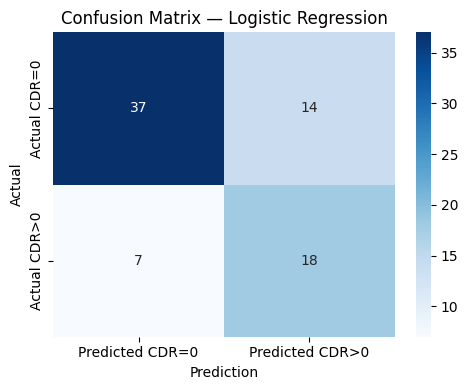

In [ ]:
# 10. Evaluate the best non-dummy model
candidate_results = results_df[results_df["Model"] != "Dummy baseline"]
best_name = candidate_results.iloc[0]["Model"] if len(candidate_results) else "Dummy baseline"
best_model = fitted_models[best_name]
y_pred = best_model.predict(X_test)

print("Selected model:", best_name)
print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["CDR = 0", "CDR > 0"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted CDR=0", "Predicted CDR>0"],
    yticklabels=["Actual CDR=0", "Actual CDR>0"]
)
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


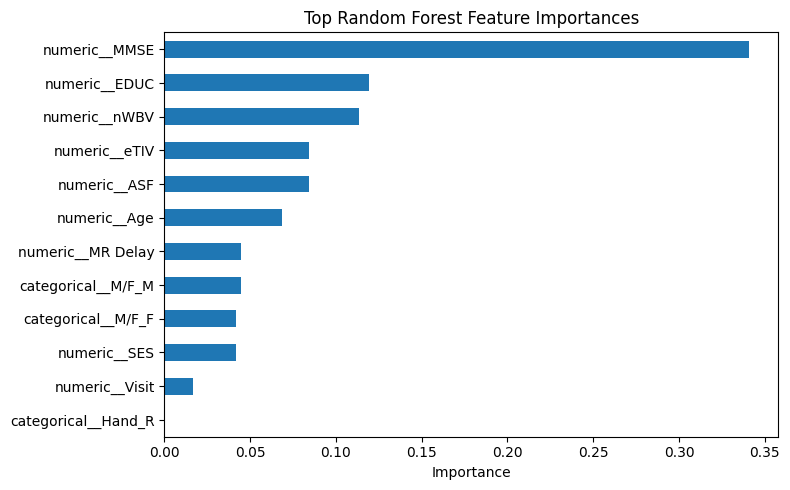

,importance
numeric__MMSE,0.340875
numeric__EDUC,0.119453
numeric__nWBV,0.113425
numeric__eTIV,0.084477
numeric__ASF,0.084397
numeric__Age,0.068377
numeric__MR Delay,0.044659
categorical__M/F_M,0.044475
categorical__M/F_F,0.041904
numeric__SES,0.041485


In [ ]:
# 11. Feature importance for Random Forest (if it is the selected model)
rf_pipe = fitted_models.get("Random Forest")
if rf_pipe is not None:
    try:
        fitted_preprocessor = rf_pipe.named_steps["preprocessor"]
        rf_model = rf_pipe.named_steps["model"]
        feature_names = fitted_preprocessor.get_feature_names_out()
        importances = pd.Series(rf_model.feature_importances_, index=feature_names)
        importances = importances.sort_values(ascending=False).head(15)

        plt.figure(figsize=(8, 5))
        importances.sort_values().plot(kind="barh")
        plt.title("Top Random Forest Feature Importances")
        plt.xlabel("Importance")
        plt.tight_layout()
        plt.show()
        display(importances.to_frame("importance"))
    except Exception as e:
        print("Could not create feature-importance chart:", repr(e))


In [ ]:
# 12. Save the selected model and metrics
import joblib

joblib.dump(best_model, "/content/oasis_cognitive_impairment_model.joblib")
results_df.to_csv("/content/model_comparison_metrics.csv", index=False)

print("Saved model: /content/oasis_cognitive_impairment_model.joblib")
print("Saved metrics: /content/model_comparison_metrics.csv")


Saved model: /content/oasis_cognitive_impairment_model.joblib
Saved metrics: /content/model_comparison_metrics.csv


## Interpretation and limitations

- This notebook predicts a simplified label derived from the CSV's CDR field. It is **not a medical diagnosis**.
- The model uses tabular variables only; it does not inspect MRI images.
- Performance depends on the exact CSV version, sample size, class balance, and available columns.
- Repeated visits from the same participant should stay in the same split. If the CSV does not provide a stable subject identifier, the split may be less reliable.
- For a true MRI + tabular multimodal project, obtain the matching OASIS MRI image files and then repair the image-loading pipeline separately.
